# A lightweight synthetic detector

The ARF is a one-dimensional **bin-averaged effective area** from EPIC-pn,
supplied as a readable text file. The RMF is an ideal Gaussian detector with
constant **50 eV FWHM** and 10 eV channels. This hybrid is not an actual XMM,
Chandra, or XRISM response. It omits backgrounds and non-Gaussian redistribution.

Run this notebook in `aux/`; products are written to the parent `example/` directory. No XSPEC or external calibration
download is needed to generate the FITS files. The text header records the
original ARF and scale. Set `area_scale` below if a smaller area is desired.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ndtr
from astropy.io import fits

area_scale = 1.0
fwhm = 0.050                  # keV
channel_width = 0.010         # keV
max_input_width = 0.005       # keV; refine native ARF bins without smoothing
tail_sigma = 7.0              # discarded Gaussian tails: < 3e-12 per row
output = Path("..").resolve()


## Effective area and incident-energy bins

Keep each native ARF bin edge. Subdividing a bin repeats its mean area;
it neither interpolates nor invents instrumental structure. Incident bins
are at most 5 eV wide. Resolution of the input model must still be checked
separately for narrow physical features.

In [2]:
lo, hi, native_area = np.loadtxt("epic-pn-area.txt", unpack=True)
assert area_scale > 0 and np.all(hi > lo) and np.all(native_area >= 0)
np.testing.assert_allclose(lo[1:], hi[:-1], atol=1e-8, rtol=0)
subdivisions = np.maximum(1, np.ceil((hi-lo)/max_input_width).astype(int))
energy_edges = np.concatenate([
    *[np.linspace(a, b, n, endpoint=False) for a, b, n in zip(lo, hi, subdivisions)],
    [hi[-1]],
]).astype("f4")
area = np.repeat(native_area * area_scale, subdivisions).astype("f4")
energy = (energy_edges[:-1].astype(float) + energy_edges[1:])/2
channel_edges = np.r_[np.arange(lo[0], hi[-1], channel_width), hi[-1]].astype("f4")
assert np.all(np.diff(energy_edges) > 0) and np.all(np.diff(channel_edges) > 0)
n_channels = len(channel_edges)-1
sigma = fwhm / (2*np.sqrt(2*np.log(2)))
print(f"{len(energy)} incident bins; {n_channels} detector channels")


4418 incident bins; 1596 detector channels


## Gaussian redistribution

For incident energy $E_i$, the probability in detector channel $j$ is

$$P_{ij}=\Phi\!\left(\frac{E_{j+1}-E_i}{\sigma}\right)
          -\Phi\!\left(\frac{E_j-E_i}{\sigma}\right),
\qquad \sigma=\frac{\mathrm{FWHM}}{2\sqrt{2\ln2}}.$$

Integrate over channel boundaries, rather than sampling the Gaussian at channel
centers. Store only the contiguous non-negligible channels in each row.
**Do not renormalize rows:** photons redistributed beyond the detector band
are lost. The RMF evaluates each incident bin at its midpoint.

In [3]:
first_channel, n_channel, redistribution = [], [], []
for incident in energy:
    first = max(0, np.searchsorted(channel_edges, incident-tail_sigma*sigma)-1)
    last = min(n_channels, np.searchsorted(channel_edges, incident+tail_sigma*sigma))
    probabilities = np.diff(ndtr((channel_edges[first:last+1].astype(float)-incident)/sigma))
    first_channel.append(first+1)  # OGIP channel numbering starts at 1
    n_channel.append(last-first)
    redistribution.append(probabilities.astype("f4"))

retained = np.array([row.sum(dtype=float) for row in redistribution])
band_probability = ndtr((channel_edges[-1]-energy)/sigma)-ndtr((channel_edges[0]-energy)/sigma)
np.testing.assert_allclose(retained, band_probability, atol=1e-7, rtol=0)
assert retained.min() < 0.8 and retained.max() <= 1+1e-7
print(f"Row sums: {retained.min():.6f}–{retained.max():.6f} (finite-band losses retained)")


Row sums: 0.509393–1.000000 (finite-band losses retained)


## Write OGIP FITS files

ARF and RMF share exactly the same incident-energy bins. `F_CHAN` and `N_CHAN`
describe one contiguous group per row; `MATRIX` is a variable-length array.
The instrument labels identify a synthetic detector; provenance stays in the
ARF history and the accompanying text file.

In [4]:
common = dict(HDUCLASS="OGIP", HDUCLAS1="RESPONSE", HDUVERS="1.3.0",
              TELESCOP="SYNTHETIC", INSTRUME="SYNTH50", FILTER="NONE")
arf = fits.BinTableHDU.from_columns([
    fits.Column(name="ENERG_LO", format="E", unit="keV", array=energy_edges[:-1]),
    fits.Column(name="ENERG_HI", format="E", unit="keV", array=energy_edges[1:]),
    fits.Column(name="SPECRESP", format="E", unit="cm2", array=area),
], name="SPECRESP")
arf.header.update(common)
arf.header.update(HDUCLAS2="SPECRESP", HDUVERS="1.1.0", AREAFAC=area_scale)
arf.header.add_history("Piecewise constant EPIC-pn area from epic-pn-area.txt; no extrapolation.")
rmf = fits.BinTableHDU.from_columns([
    fits.Column(name="ENERG_LO", format="E", unit="keV", array=energy_edges[:-1]),
    fits.Column(name="ENERG_HI", format="E", unit="keV", array=energy_edges[1:]),
    fits.Column(name="N_GRP", format="I", array=np.ones(len(energy), dtype="i2")),
    fits.Column(name="F_CHAN", format="I", array=first_channel),
    fits.Column(name="N_CHAN", format="I", array=n_channel),
    fits.Column(name="MATRIX", format="PE()", array=np.array(redistribution, dtype=object)),
], name="MATRIX")
rmf.header.update(common)
rmf.header.update(HDUCLAS2="RSP_MATRIX", HDUCLAS3="REDIST", CHANTYPE="PI",
                  DETCHANS=n_channels, TLMIN4=1, FWHM=fwhm, TAILSIG=tail_sigma)
ebounds = fits.BinTableHDU.from_columns([
    fits.Column(name="CHANNEL", format="I", array=np.arange(1, n_channels+1)),
    fits.Column(name="E_MIN", format="E", unit="keV", array=channel_edges[:-1]),
    fits.Column(name="E_MAX", format="E", unit="keV", array=channel_edges[1:]),
], name="EBOUNDS")
ebounds.header.update(common)
ebounds.header.update(HDUCLAS2="EBOUNDS", CHANTYPE="PI", DETCHANS=n_channels, TLMIN1=1)
fits.HDUList([fits.PrimaryHDU(), arf]).writeto(output/"response.arf", overwrite=True)
fits.HDUList([fits.PrimaryHDU(), rmf, ebounds]).writeto(output/"response.rmf", overwrite=True)
for filename in ("response.arf", "response.rmf"):
    with fits.open(output/filename) as hdus:
        hdus.verify("exception")
    print(filename, f"{(output/filename).stat().st_size/1024:.0f} KiB")


response.arf 59 KiB
response.rmf 650 KiB


## Inspect the area and an Fe-K line

The channel histogram has integrated probabilities. Its midpoint-based width
differs slightly from 50 eV because channels are finite; the generating
Gaussian FWHM is exactly 50 eV. No area factor belongs in the RMF itself.

Fe-K centroid: 6.399375 keV; input: 6.399375 keV


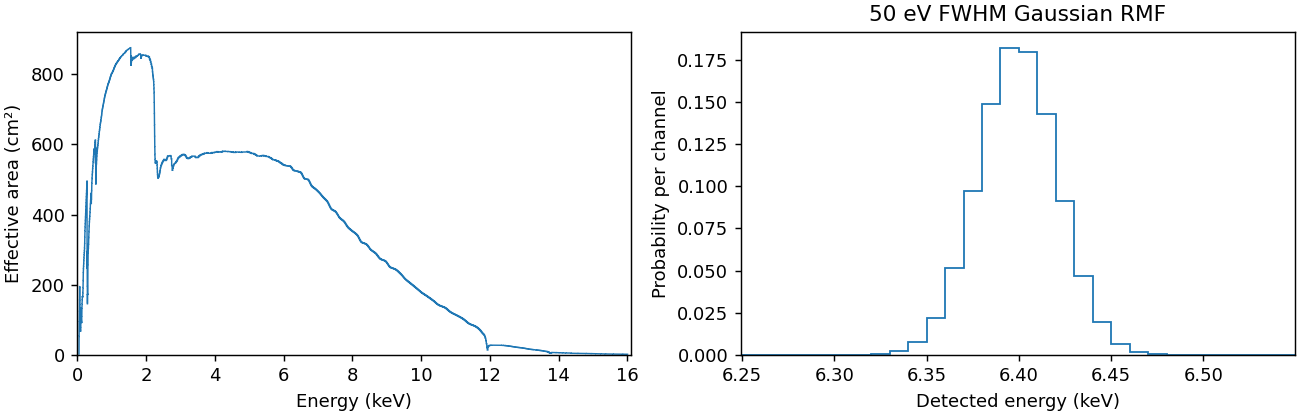

In [5]:
row = np.argmin(abs(energy-6.4))
start = first_channel[row]-1
centers = (channel_edges[:-1].astype(float)+channel_edges[1:])/2
line_energy = centers[start:start+n_channel[row]]
probability = redistribution[row].astype(float)
centroid = np.average(line_energy, weights=probability)
measured_sigma = np.sqrt(np.average((line_energy-centroid)**2, weights=probability))
assert abs(centroid-energy[row]) < 1e-5
assert abs(measured_sigma/sigma-1) < 0.02
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), constrained_layout=True)
axes[0].stairs(area, energy_edges, linewidth=0.8)
axes[0].set(xlabel="Energy (keV)", ylabel="Effective area (cm²)", xlim=(0, 16.1))
axes[1].stairs(probability, channel_edges[start:start+n_channel[row]+1])
axes[1].set(xlabel="Detected energy (keV)", ylabel="Probability per channel",
            xlim=(energy[row]-0.15, energy[row]+0.15), title="50 eV FWHM Gaussian RMF")
plt.show()
print(f"Fe-K centroid: {centroid:.6f} keV; input: {energy[row]:.6f} keV")


In XSPEC, attach both `response.rmf` and `response.arf`. Keep the model
calculation grid wider than the fitted band for WINE shifts/broadening.
Before scientific use, refine the incident-energy grid and verify stability;
this notebook defines an illustrative synthetic detector, not a calibration.
